# Учебное исследование территории: город Выборг (BlocksNet)

Этот ноутбук полностью повторяет логику примера `pipeline.ipynb` из библиотеки
[BlocksNet](https://github.com/aimclub/blocksnet), но для города **Выборг** (Выборгский район,
Ленинградская область, Россия).

Ноутбук умеет:

1. Загружать данные из OpenStreetMap (границы, дороги, ж/д, вода, зоны землепользования, здания, сервисы).
2. Нарезать территорию на городские **кварталы** и назначать им тип землепользования (land use).
3. Скачивать **готовый пеший граф** и считать **матрицу времени в пути** между кварталами (в минутах).
4. Агрегировать здания и сервисы (школы, детские сады, поликлиники) по кварталам.
5. Считать показатели: обеспеченность сервисами, плотность, морфотипы, доступность.
6. Сохранять все данные и результаты в файлы (**GeoJSON** для слоёв, **CSV** для таблиц,
   **pickle** для графа) и **переиспользовать** их при повторном запуске.

### Источники данных

- **Пространственные данные** — OpenStreetMap (через библиотеки `osmnx` и `iduedu`).
- **Пеший граф** — готовый граф из OpenStreetMap через библиотеку `IduEdu`
  (`get_accessibility_graph(boundaries, "walk")`). Интермодальный граф **не строится**.
- **Способ передвижения** — пешком (walk), скорость около 5 км/ч.
- **Время в пути** — в **минутах** (вес `time_min`).

Версия библиотеки: **BlocksNet 1.0.0a9**.


## Как пользоваться ноутбуком

- Запускайте ячейки **сверху вниз** (меню: `Run` → `Run All Cells`, либо `Shift+Enter` по одной).
- Первый запуск требует **интернета** (данные скачиваются из OpenStreetMap).
- Флаг `USE_SAVED_DATA` в ячейке ниже:
  - `True` — если файл уже есть, он читается с диска (быстро, без интернета);
  - `False` — данные скачиваются и пересчитываются заново, файлы перезаписываются.
- Все файлы сохраняются в папку `examples/data/vyborg/` (создаётся автоматически).
- В ноутбуке есть **СТОП-ячейка** ⛔ после подготовки кварталов: перед расчётом показателей
  нужно выбрать набор метрик.


In [2]:
# Импорт библиотек и настройки

import pickle
import warnings
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import geopandas as gpd
import networkx as nx
import osmnx as ox
import pandas as pd

warnings.filterwarnings("ignore")

print("blocksnet:", version("blocksnet"))
print("osmnx:", version("osmnx"))
print("geopandas:", version("geopandas"))
print("pandas:", version("pandas"))


blocksnet: 1.0.0a9
osmnx: 2.1.1
geopandas: 1.2.0
pandas: 2.3.3


In [3]:
# ===== ГЛАВНЫЕ НАСТРОЙКИ =====

# Территория исследования. При необходимости замените на русское написание:
# TERRITORY = "Выборг, Ленинградская область, Россия"
TERRITORY = "Vyborg, Leningrad Oblast, Russia"

# True  — использовать уже сохранённые файлы (быстро, офлайн);
# False — скачивать из OpenStreetMap и пересчитывать заново.
USE_SAVED_DATA = True

# Тип графа: "walk" (пешком). Другие варианты blocksnet: "drive", "intermodal".
GRAPH_TYPE = "walk"

# Виды сервисов для оценки обеспеченности.
SERVICE_TYPES = ["school", "kindergarten", "polyclinic"]

# Папка для данных и результатов.
DATA_DIR = Path("data") / "vyborg"
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Территория:", TERRITORY)
print("Папка данных:", DATA_DIR.resolve())
print("Режим USE_SAVED_DATA:", USE_SAVED_DATA)


Территория: Vyborg, Leningrad Oblast, Russia
Папка данных: C:\Users\Антон\Desktop\ТИИ\python-package-boilerplate\examples\data\vyborg
Режим USE_SAVED_DATA: True


## 1. Границы территории

Границы берём из OpenStreetMap по названию. Рабочую систему координат (метрическую, UTM)
определяем автоматически — так расстояния и площади считаются в метрах.


[load] boundaries.geojson
Рабочая СК (UTM): EPSG:32635
Найденный объект: Vyborg
Тип: city | admin_level: — | OSM id: 1572051
Площадь территории: 160.8 км²


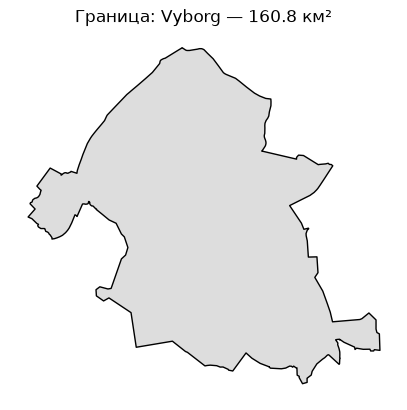

In [4]:
# Скачиваем или загружаем границы территории

boundaries_path = DATA_DIR / "boundaries.geojson"

if USE_SAVED_DATA and boundaries_path.exists():
    boundaries = gpd.read_file(boundaries_path)
    print("[load]", boundaries_path.name)
else:
    boundaries = ox.geocode_to_gdf(TERRITORY)
    boundaries.to_crs(4326).to_file(boundaries_path, driver="GeoJSON")
    print("[saved]", boundaries_path.name)

# Метрическая система координат (метры) для корректных площадей и расстояний
crs = boundaries.estimate_utm_crs()
boundaries = boundaries.to_crs(crs)

# Полигон территории в координатах WGS84 — нужен для запросов к OpenStreetMap
territory_polygon = boundaries.to_crs(4326).union_all()

print("Рабочая СК (UTM):", crs)

# --- Паспорт границы: что именно нашли и какая площадь ---
def _first(col, default="—"):
    if col in boundaries.columns:
        val = boundaries.iloc[0][col]
        if pd.notna(val):
            return val
    return default

area_km2 = boundaries.area.sum() / 1e6
boundary_name = str(_first("name", _first("display_name", "без названия")))

print("Найденный объект:", boundary_name)
print("Тип:", _first("addresstype", _first("type")),
      "| admin_level:", _first("admin_level"),
      "| OSM id:", _first("osm_id"))
print("Площадь территории: {:.1f} км²".format(area_km2))

boundaries.plot(color="#dddddd", edgecolor="black")
plt.title("Граница: {} — {:.1f} км²".format(boundary_name, area_km2))
plt.axis("off")
plt.show()


## 2. Загрузка объектов из OpenStreetMap

Скачиваем слои, из которых затем будут нарезаны кварталы и собраны характеристики:

- **дороги** (roads) — линии улиц;
- **железные дороги** (railways) — линии;
- **вода** (water) — реки, озёра, каналы (полигоны и линии);
- **зоны землепользования** (landuse) — для назначения типа квартала;
- **здания** (buildings) — для оценки населения;
- **сервисы** — школы, детские сады, поликлиники.

Каждый слой сохраняется в GeoJSON, чтобы повторный запуск шёл без интернета.


In [5]:
# Словарь тегов OpenStreetMap для дорог, ж/д и воды (как в pipeline.ipynb)

bc_tags = {
    "roads": {
        "highway": ["construction", "crossing", "living_street", "motorway", "motorway_link",
                    "motorway_junction", "pedestrian", "primary", "primary_link", "raceway",
                    "residential", "road", "secondary", "secondary_link", "services", "tertiary",
                    "tertiary_link", "track", "trunk", "trunk_link", "turning_circle",
                    "turning_loop", "unclassified"],
        "service": ["living_street", "emergency_access"],
    },
    "railways": {"railway": "rail"},
    "water": {
        "riverbank": True, "reservoir": True, "basin": True, "dock": True, "canal": True,
        "pond": True, "natural": ["water", "bay"], "waterway": ["river", "canal", "ditch"],
        "landuse": "basin", "water": "lake",
    },
}


def load_or_download(name, tags, geom_types=None):
    """Скачивает слой из OSM и сохраняет в GeoJSON, либо читает уже сохранённый файл."""
    path = DATA_DIR / f"osm_{name}.geojson"
    if USE_SAVED_DATA and path.exists():
        print(f"[load] {path.name}")
        return gpd.read_file(path).to_crs(crs)

    print(f"[download] {name}: запрос к OpenStreetMap...")
    try:
        gdf = ox.features_from_polygon(territory_polygon, tags)
        gdf = gdf.reset_index(drop=True).to_crs(crs)
    except Exception as exc:  # если объектов нет — вернём пустой слой
        print(f"[warn] не удалось получить {name}: {exc}")
        gdf = gpd.GeoDataFrame(geometry=[], crs=crs)

    if geom_types is not None and len(gdf):
        gdf = gdf[gdf.geom_type.isin(geom_types)].copy()

    gdf.to_crs(4326).to_file(path, driver="GeoJSON")
    print(f"[saved] {path.name} (объектов: {len(gdf)})")
    return gdf


water = load_or_download("water", bc_tags["water"],
                         geom_types=["Polygon", "MultiPolygon", "LineString", "MultiLineString"])
roads = load_or_download("roads", bc_tags["roads"],
                         geom_types=["LineString", "MultiLineString"])
railways = load_or_download("railways", bc_tags["railways"],
                            geom_types=["LineString", "MultiLineString"])

print("Вода:", len(water), "| Дороги:", len(roads), "| Ж/д:", len(railways))


[load] osm_water.geojson
[load] osm_roads.geojson
[load] osm_railways.geojson
Вода: 1326 | Дороги: 2299 | Ж/д: 283


[load] osm_functional_zones.geojson


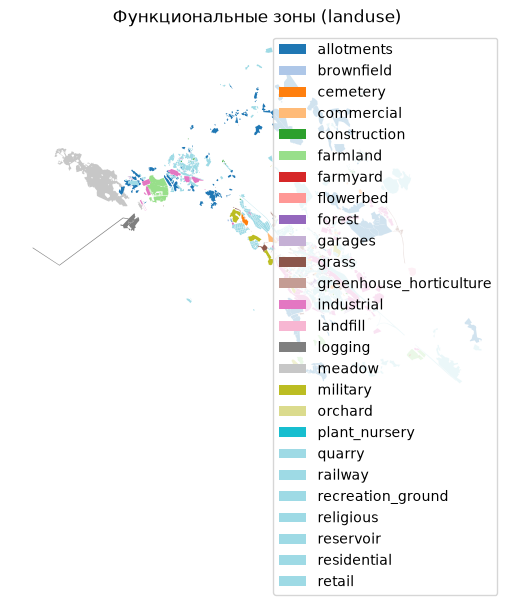

Функциональных зон: 1935


In [6]:
# Функциональные зоны (landuse) для назначения типа землепользования кварталов

functional_zones = load_or_download("functional_zones", {"landuse": True},
                                    geom_types=["Polygon", "MultiPolygon"])

if len(functional_zones) and "landuse" in functional_zones.columns:
    functional_zones = functional_zones[["geometry", "landuse"]].rename(
        columns={"landuse": "functional_zone"}
    )
    functional_zones.plot(column="functional_zone", legend=True, cmap="tab20").set_axis_off()
    plt.title("Функциональные зоны (landuse)")
    plt.show()
else:
    print("Слой функциональных зон пуст или не содержит колонку 'landuse'")

print("Функциональных зон:", len(functional_zones))


In [7]:
# Здания: определяем жилые и число этажей

buildings = load_or_download("buildings", {"building": True},
                             geom_types=["Polygon", "MultiPolygon"])

is_living_tags = ["residential", "house", "apartments", "detached", "terrace", "dormitory"]
buildings["is_living"] = buildings["building"].apply(lambda b: b in is_living_tags)

# Этажность берём из тега building:levels (если нет — будет пропуск, заполним позже)
buildings["number_of_floors"] = pd.to_numeric(buildings["building:levels"], errors="coerce")

print("Зданий всего:", len(buildings))
print("Жилых зданий:", int(buildings["is_living"].sum()))


[load] osm_buildings.geojson
Зданий всего: 14530
Жилых зданий: 1305


In [8]:
# Сервисы: школы, детские сады, поликлиники

# Какому сервису какой тег OpenStreetMap соответствует
SERVICE_OSM_TAGS = {
    "school": {"amenity": "school"},
    "kindergarten": {"amenity": "kindergarten"},
    "polyclinic": {"amenity": "clinic"},
}

services = {}
for st in SERVICE_TYPES:
    services[st] = load_or_download(
        f"service_{st}", SERVICE_OSM_TAGS[st],
        geom_types=["Polygon", "MultiPolygon", "Point", "MultiPoint"],
    )
    print("  ", st, "— объектов:", len(services[st]))


[load] osm_service_school.geojson
   school — объектов: 16
[load] osm_service_kindergarten.geojson
   kindergarten — объектов: 26
[load] osm_service_polyclinic.geojson
   polyclinic — объектов: 7


## 3. Подготовка кварталов

Делим территорию линиями (дороги, ж/д) и вычитаем воду. На выходе — слой городских
**кварталов**. Затем каждому кварталу назначаем преобладающий тип **землепользования**
(land use) на основе функциональных зон.


[load] blocks.geojson
[saved] blocks.geojson
Кварталов: 1143


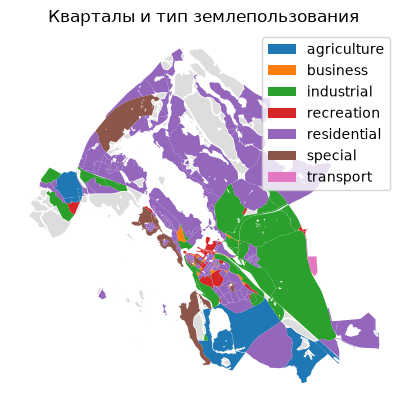

In [9]:
# Нарезка кварталов + назначение землепользования

from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse

blocks_path = DATA_DIR / "blocks.geojson"

if USE_SAVED_DATA and blocks_path.exists():
    blocks = gpd.read_file(blocks_path).to_crs(crs)
    print("[load]", blocks_path.name)
else:
    # 1) Готовим линии и полигоны из дорог, ж/д и воды
    lines, polygons = preprocess_urban_objects(roads, railways, water)

    # 2) Режем территорию на кварталы
    blocks = cut_urban_blocks(boundaries, lines, polygons)

    # 3) Правила перевода функциональных зон OSM в перечисление LandUse
    rules = {
        "commercial": LandUse.BUSINESS, "industrial": LandUse.INDUSTRIAL,
        "cemetery": LandUse.SPECIAL, "garages": LandUse.INDUSTRIAL,
        "residential": LandUse.RESIDENTIAL, "retail": LandUse.BUSINESS,
        "grass": LandUse.RECREATION, "farmland": LandUse.AGRICULTURE,
        "construction": LandUse.SPECIAL, "brownfield": LandUse.INDUSTRIAL,
        "forest": LandUse.RECREATION, "recreation_ground": LandUse.RECREATION,
        "religious": LandUse.SPECIAL, "flowerbed": LandUse.RECREATION,
        "military": LandUse.SPECIAL, "landfill": LandUse.TRANSPORT,
    }
    if len(functional_zones):
        blocks = assign_land_use(blocks, functional_zones, rules)
    else:
        print("[warn] функциональные зоны пусты — тип землепользования не назначен")

# assign_land_use кладёт в колонку объекты перечисления LandUse,
# а карту (легенду) и GeoJSON рисуют/сохраняют только текст и числа.
# Приводим значения к тексту: "LandUse.AGRICULTURE" -> "agriculture".
if "land_use" in blocks.columns:
    blocks["land_use"] = blocks["land_use"].apply(
        lambda v: v if pd.isna(v) else (v.value if hasattr(v, "value") else str(v).split(".")[-1].lower())
    )

blocks.to_crs(4326).to_file(blocks_path, driver="GeoJSON")
print("[saved]", blocks_path.name)

print("Кварталов:", len(blocks))

if "land_use" in blocks.columns:
    ax = blocks.plot(color="#dddddd", edgecolor="white")
    blocks.plot(column="land_use", legend=True, ax=ax).set_axis_off()
    plt.title("Кварталы и тип землепользования")
else:
    blocks.plot(color="#dddddd", edgecolor="white").set_axis_off()
    plt.title("Кварталы")
plt.show()


## Справочник: метрики BlocksNet и показатели `pipeline.ipynb`

Это справка для чтения — расчёты здесь не запускаются.

### Часть 1. Какие показатели есть в BlocksNet

BlocksNet считает не одну цифру, а набор городских показателей — как «анализы» для города.
Считаются они по кварталам (blocks) и собраны в группы:

1. **Доступность** (`analysis.network.accessibility`) — сколько минут от квартала до других мест. Единицы: минуты (или метры для расстояний).
2. **Связность** (`analysis.network.connectivity`) — обратная доступность: чем ближе всё вокруг, тем выше. Условный индекс (1/мин).
3. **Обеспеченность сервисами** (`analysis.provision`) — хватает ли жителям школ, садов, поликлиник рядом. Доля 0–1 (1 = потребность закрыта).
4. **Плотность и застройка** (`analysis.indicators.density`, `development`) — FSI, GSI, MXI, этажность, доли жилья. Коэффициенты и м².
5. **Морфотипы** (`analysis.morphotypes`) — тип застройки по виду (низкая, высотная, сплошная, открытая). Текстовые категории.
6. **Геометрия кварталов** (`analysis.geometry`) — площадь, периметр, размеры, форма. м², м, коэффициент вытянутости.
7. **Разнообразие и коллокация сервисов** (`analysis.diversity.shannon`, `analysis.services`) — разнообразие сервисов, их количество, плотность, соседство. Индекс (энтропия), количество, кол-во/м², доля 0–1.
8. **Центральность** (`analysis.centrality`) — где центры города: по населению и по сервисам. Индекс 0–1.
9. **Транспорт и социально-экономика** (`analysis.indicators.socio_economic`) — площадь, урбанизация, население, плотность, дорожная сеть, инженерные и социальные объекты. км², чел., чел/км², км/км², минуты, количество.
10. **Землепользование** (`analysis.land_use`) — доли типов и «похожесть» кварталов. Доли 0–1.
11. **Свободные территории** (`analysis.vacant_area`) — пустующие участки внутри кварталов (потенциал застройки). м².
12. **OD-матрица и загруженность дорог** (`analysis.network.origin_destination`, `road_congestion`) — кто куда едет и какие улицы перегружены. Условные поездки и нагрузка.
13. **Отношения между кварталами** (`blocksnet.relations`) — матрицы времени и расстояний, граф соседства. Минуты, метры, граф.

Важно: разным показателям нужны разные данные. Плотности и морфотипам — только кварталы и площади зданий; обеспеченности — ещё население и сервисы; транспорту — дорожный граф. Часть социально-экономических показателей BlocksNet сам не считает — их нужно подать готовыми числами (экономика, экология, статистика).

### Часть 2. Показатели из `pipeline.ipynb` (официальный пример)

`pipeline.ipynb` — базовый маршрут BlocksNet. Он считает такие показатели:

| Показатель | Функция | Что возвращает | Единицы | Что скажет о Выборге |
|---|---|---|---|---|
| Кварталы | `cut_urban_blocks` | слой кварталов | геометрия | сколько кварталов и какой они формы |
| Землепользование | `assign_land_use` | колонка `land_use` + доли (residential, business, recreation, industrial, transport, special, agriculture) и `share` | доли 0–1 | где жильё, заводы, зелень |
| Матрица доступности | `calculate_accessibility_matrix` | матрица квартал × квартал | минуты | сколько ехать из каждого квартала в каждый |
| Обеспеченность (напр. школы) | `competitive_provision` | demand, capacity и их части, provision_strong, provision_weak | доли 0–1 и количество | где дефицит школ рядом с жильём |
| Плотность застройки | `calculate_density_indicators` | site_area, footprint_area, build_floor_area, living_area, non_living_area, fsi, gsi, mxi, l, osr, share_living, share_non_living | м² и коэффициенты | как плотно и высоко застроен город |
| Морфотипы Spacematrix | `get_spacematrix_morphotypes` | l, fsi, mxi, cluster, morphotype | категория-текст | делит застройку на типы автоматически |
| Морфотипы Strelka | `get_strelka_morphotypes` | l, fsi, mxi, morphotype | категория-текст | другой взгляд на тип городской ткани |
| Доступность территории | `area_accessibility` | колонка area_accessibility | минуты | средневзвешенное время в пути, общая связанность |

Как читать главные термины:

- **FSI** — плотность застройки: сколько «этажей площади» на единицу земли (больше = плотнее).
- **GSI** — доля пятна застройки: какая часть территории занята зданиями (0…1).
- **MXI** — «микс» жилых и нежилых помещений (0…1).
- **l** — средняя этажность застройки.
- **OSR** — сколько открытого пространства на застроенную площадь.
- **share_living / share_non_living** — доля жилой и нежилой площади зданий.
- **provision_strong** — доля потребности, закрытая сервисами в пределах норматива; **provision_weak** — с учётом более далёких сервисов.

Кроме показателей, пример готовит данные (это не метрики, а подготовка): `impute_buildings` (восстановить параметры зданий), `impute_services` (восстановить ёмкость сервисов), `aggregate_objects` (суммировать объекты по кварталам), `get_accessibility_graph` (построить граф).

### Часть 3. Что это даст про наш город

- Доступность и матрица → видно, какие кварталы «отрезаны», а где город связан хорошо.
- Обеспеченность → карта дефицита школ, садов, поликлиник.
- Плотность и морфотипы → тип застройки Выборга (старая низкая, советские микрорайоны, новая высотная) и где она расположена.
- Центральность и связность → где настоящий центр и главные узлы города.
- Свободные территории → где есть площадки под новое строительство.
- OD и загруженность → какие улицы нагружены и куда едет народ.

> По умолчанию считаем базовый набор из `pipeline.ipynb` (строка «Матрица доступности» и ниже в таблице). Остальное — по желанию.


---
# ⛔ СТОП: кварталы готовы

**Дальше — расчёт показателей. Перед тем как продолжить, выберите набор метрик.**

### Доступные показатели (BlocksNet 1.0.0a9)

**Базовый набор из `pipeline.ipynb`:**

| Показатель | Функция | Что показывает |
|---|---|---|
| Обеспеченность сервисами (provision) | `competitive_provision` | доля потребности, закрытая сервисами поблизости |
| Плотность (density) | `calculate_density_indicators` | FSI, GSI, MXI, этажность, доля жилья |
| Морфотипы Spacematrix | `get_spacematrix_morphotypes` | тип застройки (плотная/открытая/низкая и т.д.) |
| Морфотипы Strelka | `get_strelka_morphotypes` | тип городской ткани |
| Доступность территории | `area_accessibility` | средневзвешенное время в пути по городу |

**Дополнительно доступно в версии 1.0.0a9:**

- `blocksnet.analysis.network.connectivity` — связность кварталов;
- центральность населения и сервисов (`analysis.centrality`);
- транспортные и социально-экономические индикаторы
  (`calculate_transport_indicators` и др.);
- плотность сервисов, разнообразие (Shannon), коллокация сервисов.

---

### 👉 Что нужно от вас

Ответьте, какие показатели считать. По умолчанию (если ничего не менять) ноутбук ниже уже
считает **базовый набор pipeline**: обеспеченность по 3 сервисам, плотность, морфотипы
Spacematrix и Strelka и доступность территории.

Если хотите добавить/убрать метрики — скажите, и я допишу соответствующие ячейки.

**Продолжайте запуск со следующей ячейки только после этого.**


## 4. Пеший граф доступности

**Источник графа:** OpenStreetMap, загружается готовым графом через библиотеку **IduEdu**
(входит в зависимости BlocksNet). **Способ передвижения:** пешком (walk). Интермодальный
граф не строится.

Граф сохраняется в формате **pickle** (`.pkl`), потому что в нём есть геометрия рёбер
(shapely-объекты), которую формат GeoJSON хранить не умеет. Матрица доступности — это таблица
(без геометрии), поэтому её сохраняем в **CSV**.


In [10]:
# Скачивание (или загрузка) пешего графа

from blocksnet.relations import get_accessibility_graph

graph_path = DATA_DIR / "walk_graph.pkl"

if USE_SAVED_DATA and graph_path.exists():
    with open(graph_path, "rb") as f:
        graph = pickle.load(f)
    print("[load]", graph_path.name)
else:
    print("[download] построение пешего графа из OpenStreetMap...")
    graph = get_accessibility_graph(boundaries, GRAPH_TYPE)
    with open(graph_path, "wb") as f:
        pickle.dump(graph, f)
    print("[saved]", graph_path.name)

print("Узлов (точек улиц):", graph.number_of_nodes())
print("Рёбер (участков):", graph.number_of_edges())
print("Вес ребра (время):", "time_min (минуты)")


[load] walk_graph.pkl
Узлов (точек улиц): 19945
Рёбер (участков): 51768
Вес ребра (время): time_min (минуты)


## 5. Матрица доступности (время в пути между кварталами)

Считаем для каждой пары кварталов **минимальное время пешего пути в минутах** между их
центрами. Значение на пересечении строки `i` и столбца `j` — сколько минут идти из квартала
`i` в квартал `j`.


In [11]:
# Расчёт (или загрузка) матрицы доступности

from blocksnet.relations import calculate_accessibility_matrix

acc_path = DATA_DIR / "accessibility_matrix.csv"

if USE_SAVED_DATA and acc_path.exists():
    acc_mx = pd.read_csv(acc_path, index_col=0)
    # CSV не хранит типы данных — возвращаем целочисленные индексы, как у кварталов
    acc_mx.index = acc_mx.index.astype(blocks.index.dtype)
    acc_mx.columns = acc_mx.columns.astype(blocks.index.dtype)
    print("[load]", acc_path.name)
else:
    print("[compute] расчёт матрицы доступности по пешему графу...")
    acc_mx = calculate_accessibility_matrix(blocks, graph)
    acc_mx.to_csv(acc_path)
    print("[saved]", acc_path.name)

print("Размер матрицы:", acc_mx.shape, "(кварталов × кварталов)")
print("Среднее время пешего пути между кварталами, мин:",
      round(float(acc_mx.values[acc_mx.values > 0].mean()), 2))
acc_mx.head()


[load] accessibility_matrix.csv
Размер матрицы: (1143, 1143) (кварталов × кварталов)
Среднее время пешего пути между кварталами, мин: 108.55


,0,1,2,3,4,5,6,7,8,9,...,1133,1134,1135,1136,1137,1138,1139,1140,1141,1142
0,0.00,0.00,9.89,25.53,161.0,121.7,20.05,21.78,133.2,92.94,...,46.75,44.62,46.4,44.25,44.16,62.12,51.56,67.1,67.06,66.56
1,0.00,0.00,10.17,25.81,161.2,122.0,20.33,22.06,133.5,93.20,...,47.03,44.88,46.7,44.53,44.44,62.40,51.80,67.4,67.30,66.90
2,9.89,10.17,0.00,19.92,170.4,131.0,19.16,20.81,142.6,102.25,...,55.22,53.10,54.9,52.75,52.66,70.60,60.03,75.6,75.56,75.06
3,25.53,25.81,19.92,0.00,183.2,143.9,26.39,19.75,155.4,115.06,...,64.30,62.20,64.0,61.84,61.75,79.70,69.10,84.7,84.60,84.20
4,161.00,161.20,170.40,183.20,0.0,42.1,169.00,173.20,130.9,73.25,...,137.90,140.00,137.6,139.60,139.50,153.50,167.10,151.6,151.60,151.10


## 6. Агрегация зданий по кварталам

Заполняем пропуски у зданий (площадь, этажность, жилая площадь, население) и суммируем
их внутри каждого квартала. На выходе — население и площади по кварталам.


In [12]:
# Заполнение пропусков и агрегация зданий

from blocksnet.preprocessing.imputing import impute_buildings
from blocksnet.blocks.aggregation import aggregate_objects

bb_path = DATA_DIR / "buildings_blocks.geojson"

if USE_SAVED_DATA and bb_path.exists():
    buildings_blocks = gpd.read_file(bb_path).to_crs(crs)
    print("[load]", bb_path.name)
elif len(buildings):
    buildings = impute_buildings(buildings, default_living_demand=30)
    buildings_blocks = aggregate_objects(blocks, buildings)[0]
    buildings_blocks.to_crs(4326).to_file(bb_path, driver="GeoJSON")
    print("[saved]", bb_path.name)
    print("Оценка населения города, чел.:", int(buildings_blocks["population"].sum()))
else:
    buildings_blocks = blocks.copy()
    print("Нет зданий — пропускаем")

buildings_blocks.head()


[load] buildings_blocks.geojson


,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population,count,geometry
0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,"POLYGON ((594369.087 6732214.75, 594378.721 67..."
1,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,"POLYGON ((594577.156 6732291.106, 594567.68 67..."
2,3.0,9.0,2796.959574,4053.442900,2382.391525,1671.051375,79.0,7.0,"POLYGON ((593808.811 6732922.251, 593860.623 6..."
3,17.0,113.0,25680.586355,28093.596554,5001.891204,23091.705351,159.0,100.0,"POLYGON ((593970.897 6732943.38, 593960.603 67..."
4,1.0,325.0,22399.456578,22399.456578,76.002126,22323.454452,2.0,325.0,"POLYGON ((602571.758 6727763.229, 602520.116 6..."


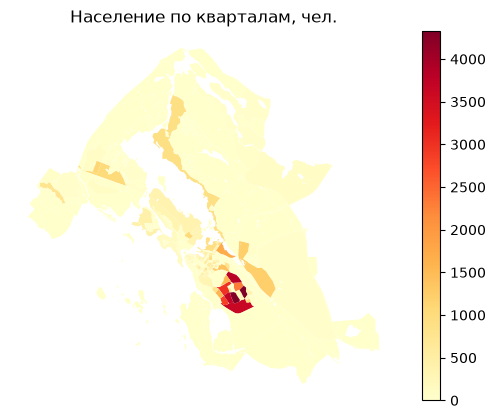

In [13]:
# Карта населения по кварталам
if "population" in buildings_blocks.columns:
    buildings_blocks.plot("population", legend=True, cmap="YlOrRd").set_axis_off()
    plt.title("Население по кварталам, чел.")
    plt.show()


## 7. Агрегация сервисов по кварталам

Для каждого типа сервиса (школа, детский сад, поликлиника) заполняем ёмкость и суммируем
внутри кварталов.


In [14]:
# Заполнение и агрегация сервисов по кварталам

from blocksnet.preprocessing.imputing import impute_services

services_blocks = {}
for st in SERVICE_TYPES:
    path = DATA_DIR / f"{st}_blocks.geojson"

    if USE_SAVED_DATA and path.exists():
        services_blocks[st] = gpd.read_file(path).to_crs(crs)
        print(f"[load] {path.name}")
        continue

    gdf = services[st]
    if len(gdf) == 0:
        print(f"[skip] нет объектов для сервиса '{st}'")
        continue

    gdf = impute_services(gdf, st)
    s_blocks = aggregate_objects(blocks, gdf)[0]
    s_blocks.to_crs(4326).to_file(path, driver="GeoJSON")
    services_blocks[st] = s_blocks

    total_capacity = int(s_blocks["capacity"].sum()) if "capacity" in s_blocks.columns else 0
    print(f"[saved] {path.name} (суммарная ёмкость: {total_capacity})")


[load] school_blocks.geojson
[load] kindergarten_blocks.geojson
[load] polyclinic_blocks.geojson


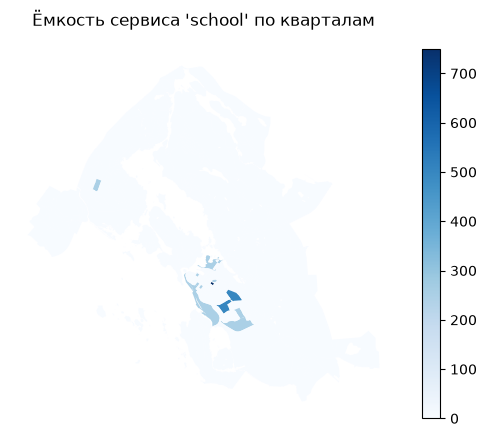

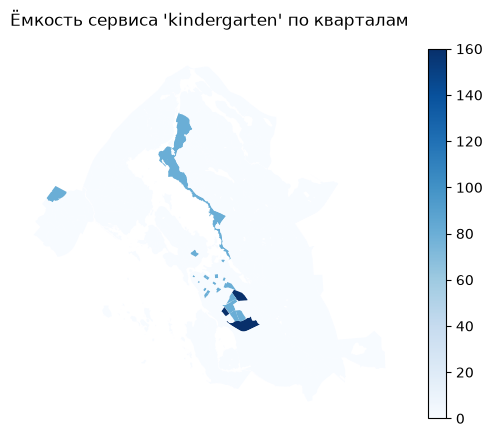

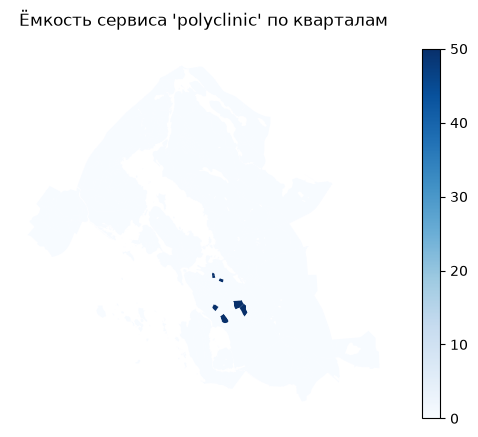

In [15]:
# Карты ёмкости сервисов по кварталам
for st, s_blocks in services_blocks.items():
    if "capacity" in s_blocks.columns:
        s_blocks.plot("capacity", legend=True, cmap="Blues").set_axis_off()
        plt.title(f"Ёмкость сервиса '{st}' по кварталам")
        plt.show()


## 8. Расчёт показателей

Ниже — базовый набор показателей из `pipeline.ipynb`: обеспеченность сервисами, плотность
застройки, морфотипы (Spacematrix и Strelka) и доступность территории. Для каждого
показателя есть и **расчёт**, и **отображение** (таблица и/или карта). Все результаты
сохраняются в файлы.


In [26]:
# Обеспеченность сервисами (competitive provision)

from blocksnet.analysis.provision import competitive_provision
from blocksnet.config import service_types_config

provision = {}
provision_links = {}

for st in SERVICE_TYPES:
    if st not in services_blocks:
        print(f"[skip] нет данных сервиса '{st}'")
        continue

    # Таблица спроса (население) и предложения (ёмкость сервисов) по кварталам
    df = buildings_blocks[["population"]].join(
        services_blocks[st][["capacity"]], how="left"
    ).fillna(0)

    # Нормативы спроса и доступности берём из конфигурации BlocksNet
    params = service_types_config[st]
    demand = params["demand"]
    accessibility = params["accessibility"]

    prov_df, links_df = competitive_provision(df, acc_mx, accessibility, demand)
    provision[st] = prov_df
    provision_links[st] = links_df
    print(f"{st}: средняя обеспеченность = "
          f"{round(float(prov_df['provision_strong'].mean()), 3)}")

# Сохраняем таблицу обеспеченности (итоговая доля по каждому сервису)
if provision:
    prov_table = pd.DataFrame({st: p["provision_strong"] for st, p in provision.items()})
    prov_table.to_csv(DATA_DIR / "provision.csv")
    print("[saved] provision.csv")

    # Полная таблица: спрос, ёмкость и их части + provision_strong / provision_weak
    prov_full = pd.concat(provision, names=["service", "block"]).reset_index()
    prov_full.to_csv(DATA_DIR / "provision_full.csv", index=False)
    print("[saved] provision_full.csv")
    prov_table.head()


2026-10-18 13:22:19.044 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-18 13:22:19.046 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-18 13:22:19.058 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-18 13:22:19.070 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-10-18 13:22:19.161 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished
2026-10-18 13:22:19.168 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-18 13:22:19.169 | WARNING  | blocksnet.analysi

school: средняя обеспеченность = 0.209
kindergarten: средняя обеспеченность = 0.269
polyclinic: средняя обеспеченность = 0.078
[saved] provision.csv
[saved] provision_full.csv


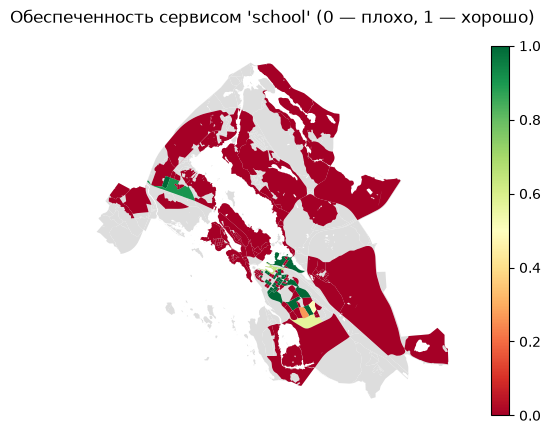

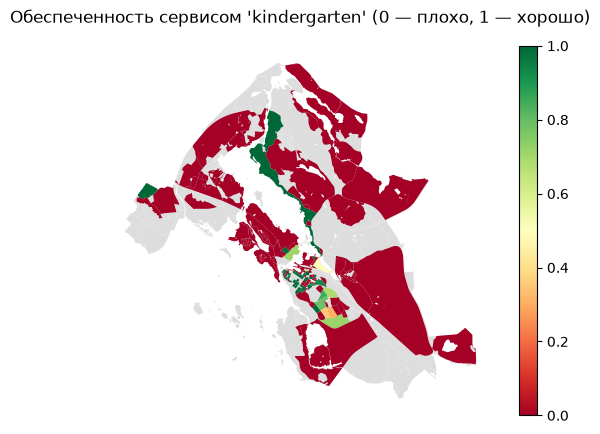

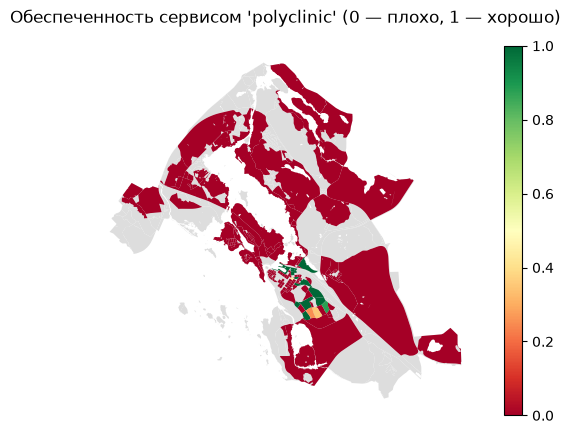

In [17]:
# Карты обеспеченности по каждому сервису
for st, prov_df in provision.items():
    ax = blocks.plot(color="#dddddd")
    blocks.join(prov_df).plot("provision_strong", ax=ax, cmap="RdYlGn",
                              vmin=0, vmax=1, legend=True)
    ax.set_axis_off()
    plt.title(f"Обеспеченность сервисом '{st}' (0 — плохо, 1 — хорошо)")
    plt.show()


## 8.1. Детали обеспеченности: связи «спрос → предложение»

Помимо итоговой доли обеспеченности (`provision_strong`), функция `competitive_provision`
возвращает таблицу связей: какие кварталы закрывают потребность в сервисе других кварталов
и на сколько мест. Колонки: `source` (квартал-потребитель), `target` (квартал-поставщик),
`value` (переданная ёмкость).


In [18]:
# Связи «спрос → предложение» по каждому сервису

for st, links_df in provision_links.items():
    print(f"--- {st}: связей {len(links_df)} ---")
    print(links_df.head(5))

# Сохраняем все связи в одну таблицу
if provision_links:
    all_links = pd.concat(provision_links, names=["service", "source", "target"]).reset_index()
    all_links.to_csv(DATA_DIR / "provision_links.csv", index=False)
    print("[saved] provision_links.csv")
    all_links.head(10)


--- school: связей 38 ---
               value
source target       
74     35       78.0
78     35       79.0
       156      12.0
       248      21.0
79     156      30.0
--- kindergarten: связей 39 ---
               value
source target       
6      13       15.0
74     201      40.0
79     78       23.0
81     593       7.0
100    254      69.0
--- polyclinic: связей 13 ---
               value
source target       
74     563       4.0
78     265      11.0
       563       2.0
79     265       8.0
100    563      17.0
[saved] provision_links.csv


In [19]:
# Показатели плотности застройки

from blocksnet.analysis.indicators import calculate_density_indicators

buildings_blocks["site_area"] = buildings_blocks.area
density_df = calculate_density_indicators(buildings_blocks)
density_df.to_csv(DATA_DIR / "density.csv")
print("[saved] density.csv")
density_df.head()


[saved] density.csv


,site_area,footprint_area,build_floor_area,living_area,non_living_area,fsi,gsi,mxi,l,osr,share_living,share_non_living
0,4.719343e+03,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,inf,NaN,NaN
1,6.916406e+03,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,inf,NaN,NaN
2,6.066114e+04,2796.959574,4053.442900,2382.391525,1671.051375,0.066821,0.046108,0.587745,1.449232,14.275317,0.851779,0.597453
3,3.319066e+05,25680.586355,28093.596554,5001.891204,23091.705351,0.084643,0.077373,0.178044,1.093962,10.900208,0.194773,0.899189
4,2.526096e+06,22399.456578,22399.456578,76.002126,22323.454452,0.008867,0.008867,0.003393,1.000000,111.774871,0.003393,0.996607


## 8.2. Отображение показателей плотности

`calculate_density_indicators` считает для каждого квартала:

- **FSI** — плотность застройки (этажная площадь / площадь земли);
- **GSI** — доля территории, занятой застройкой (0…1);
- **MXI** — доля жилых помещений в застройке (0…1);
- **l** — средняя этажность застройки;
- **OSR** — открытое пространство в расчёте на застроенную площадь.

Ниже — карты по этим показателям и средние значения по городу.


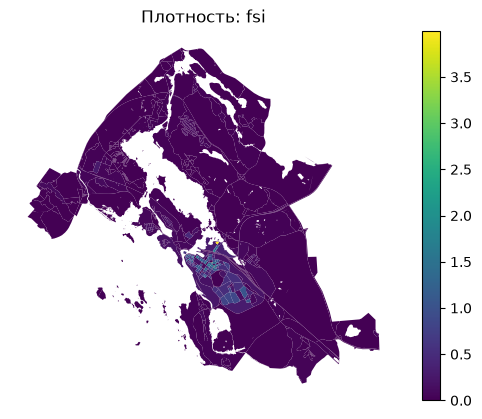

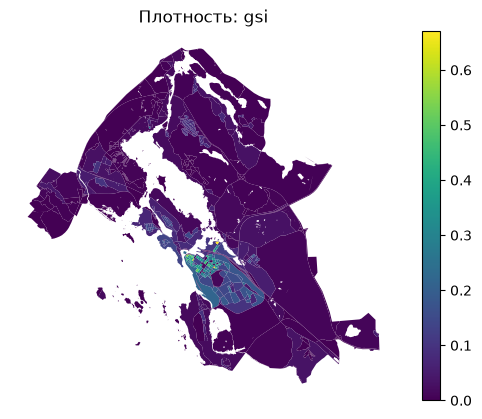

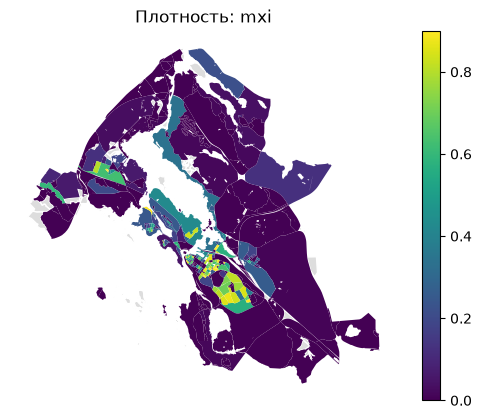

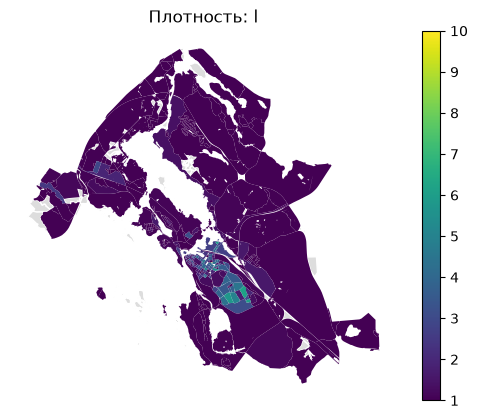

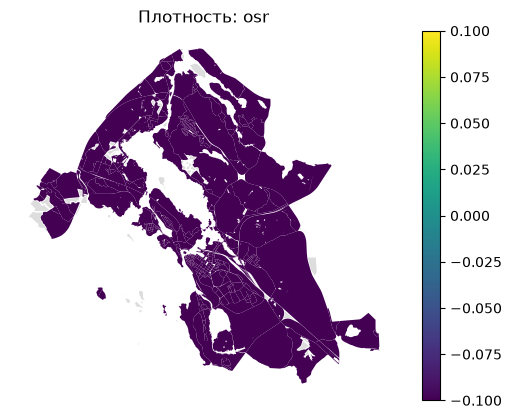

Средние значения показателей плотности по городу:


fsi    0.101
gsi    0.044
mxi    0.224
l      1.618
osr      inf
dtype: float64

In [20]:
# Карты показателей плотности и средние значения по городу

density_cols = ["fsi", "gsi", "mxi", "l", "osr"]
present_cols = [c for c in density_cols if c in density_df.columns]

for col in present_cols:
    ax = blocks.plot(color="#dddddd", edgecolor="white")
    blocks.join(density_df[[col]]).plot(col, ax=ax, cmap="viridis", legend=True)
    ax.set_axis_off()
    plt.title(f"Плотность: {col}")
    plt.show()

print("Средние значения показателей плотности по городу:")
density_df[present_cols].mean().round(3)


[saved] morphotypes_spacematrix.csv, morphotypes_strelka.csv


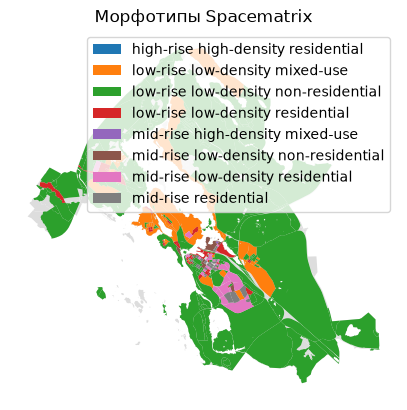

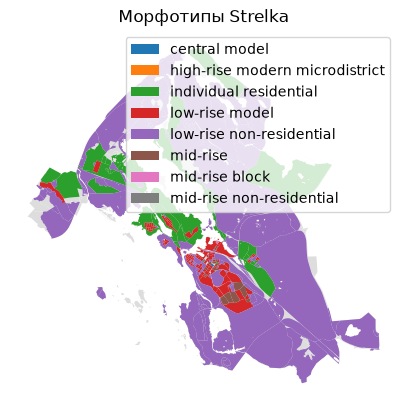

In [21]:
# Морфотипы застройки: Spacematrix и Strelka

from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
strelka_df = get_strelka_morphotypes(density_df)

spacematrix_df.to_csv(DATA_DIR / "morphotypes_spacematrix.csv")
strelka_df.to_csv(DATA_DIR / "morphotypes_strelka.csv")
print("[saved] morphotypes_spacematrix.csv, morphotypes_strelka.csv")

ax = blocks.plot(color="#dddddd")
blocks.join(spacematrix_df).plot("morphotype", legend=True, ax=ax)
ax.set_axis_off()
plt.title("Морфотипы Spacematrix")
plt.show()

ax = blocks.plot(color="#dddddd")
blocks.join(strelka_df).plot("morphotype", legend=True, ax=ax)
ax.set_axis_off()
plt.title("Морфотипы Strelka")
plt.show()


## 8.3. Таблицы морфотипов

- `spacematrix_df` — кварталы с колонками `cluster` (номер кластера) и `morphotype` (тип);
- `spacematrix_clusters` — описание кластеров (медианные FSI/GSI/MXI и название морфотипа);
- `strelka_df` — морфотип квартала по методике Strelka.


In [22]:
# Просмотр таблиц морфотипов и сохранение описания кластеров

spacematrix_clusters.to_csv(DATA_DIR / "spacematrix_clusters.csv")
print("[saved] spacematrix_clusters.csv\n")

print("Описание кластеров (spacematrix_clusters):")
print(spacematrix_clusters, "\n")
print("Кварталы (spacematrix_df), первые строки:")
print(spacematrix_df.head(), "\n")
print("Кварталы (strelka_df), первые строки:")
print(strelka_df.head())


[saved] spacematrix_clusters.csv

Описание кластеров (spacematrix_clusters):
                 l       fsi       mxi l_interpretation fsi_interpretation  \
cluster                                                                      
0         1.051455  0.083145  0.255633         low-rise        low-density   
1         3.119201  0.763895  0.813835         mid-rise        low-density   
2         1.000000  0.047340  0.000000         low-rise        low-density   
3         3.893669  1.322148  0.760875         mid-rise               None   
4         1.667292  0.348491  0.582378         low-rise        low-density   
5         5.958726  3.998842  0.224198         mid-rise       high-density   
6         3.000000  0.254512  0.000000         mid-rise        low-density   
7         5.392853  1.080364  0.891669         mid-rise               None   
8        10.000000  3.213678  0.900000        high-rise       high-density   
9         2.079385  0.610161  0.000000         low-rise        lo

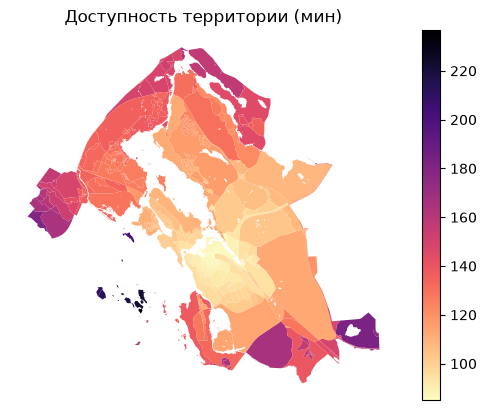

,area_accessibility
0,93.351226
1,93.641294
2,97.651666
3,102.807698
4,182.476647


In [23]:
# Доступность территории (средневзвешенное время в пути по кварталам)
# В BlocksNet 1.0.0a9 модуль доступности находится в blocksnet.analysis.network
from blocksnet.analysis.network import area_accessibility

area_acc = area_accessibility(acc_mx, buildings_blocks)
blocks.join(area_acc).plot("area_accessibility", legend=True, cmap="magma_r").set_axis_off()
plt.title("Доступность территории (мин)")
plt.show()

area_acc.head()


In [24]:
# Итоговый слой: кварталы + все показатели → GeoJSON

result = blocks.copy()

for st, prov_df in provision.items():
    result[f"provision_{st}"] = prov_df["provision_strong"].reindex(result.index)

result = result.join(area_acc)
result = result.join(spacematrix_df[["morphotype"]].rename(columns={"morphotype": "spacematrix"}))
result = result.join(strelka_df[["morphotype"]].rename(columns={"morphotype": "strelka"}))
result = result.join(density_df[["fsi", "gsi", "mxi", "l", "osr"]])

out_path = DATA_DIR / "vyborg_metrics.geojson"
result.to_crs(4326).to_file(out_path, driver="GeoJSON")
print("[saved]", out_path.name)
print("Колонки итогового слоя:", list(result.columns))


[saved] vyborg_metrics.geojson
Колонки итогового слоя: ['residential', 'business', 'recreation', 'industrial', 'transport', 'special', 'agriculture', 'land_use', 'share', 'geometry', 'provision_school', 'provision_kindergarten', 'provision_polyclinic', 'area_accessibility', 'spacematrix', 'strelka', 'fsi', 'gsi', 'mxi', 'l', 'osr']


## 9. Выводы по результатам расчётов

Ниже — 5 главных выводов о Выборге по данным запуска ноутбука. Для каждого указано, какие числа и какая карта (файл) это подтверждают.

### 1. Население: около 72 тысяч человек, сосредоточено в 191 квартале из 1143

- Суммарное население по зданиям: **71 777 чел.** (ячейка агрегации зданий печатает «Оценка населения города, чел.: 71777»). Это почти совпадает с реальным населением Выборга (~72 тыс.), значит оценка из OSM + дозаполнение (30 м² жилья на человека) правдоподобна.
- Люди распределены очень неравномерно: население есть только в **191 квартале из 1143**, самый населённый квартал — около **4 331 чел.**
- Подтверждают: ячейка агрегации зданий (`buildings_blocks.geojson`, колонка `population`) и карта «Население по кварталам, чел.».

### 2. Обеспеченность сервисами неполная; хуже всего — поликлиники

Нормативы BlocksNet: школа — доступность 15 мин, садик — 7 мин, поликлиника — 15 мин.

- Закрыто в пределах норматива (с учётом числа жителей):
  - **школы — ≈ 46 %** потребности (простое среднее по кварталам 0,209);
  - **детские сады — ≈ 43 %** (среднее 0,269);
  - **поликлиники — ≈ 37 %** (среднее 0,078) — самый дефицитный сервис.
- Доля жилых кварталов вообще без нормативной доступности (`provision_strong = 0`): школы — **78 %**, садики — **71 %**, поликлиники — **91 %**.
- Переток мест между кварталами: школы — **2 425** (38 связей), садики — **723** (39), поликлиники — **220** (13).
- Подтверждают: ячейка обеспеченности (печатает средние по каждому сервису), `provision.csv`, карты «Обеспеченность сервисом …» (зелёный — хорошо, красный — плохо), ячейка связей «спрос → предложение» и `provision_links.csv`.
- Оговорка: ёмкость сервисов берётся из OSM и дозаполняется, поэтому проценты ориентировочные; надёжнее смотреть, где хуже, а где лучше.

### 3. Плотность застройки: город в основном низкоплотный, но жильё плотнее

- Застроено только **406 кварталов из 1143**; у остальных плотность нулевая (леса, вода, пустыри).
- Среди застроенных: **FSI ≈ 0,28** (медиана 0,08, максимум **4,0**), **GSI ≈ 0,12** (максимум **0,67**), этажность **l ≈ 1,6** (максимум **10**).
- С поправкой на население картина плотнее: **FSI ≈ 0,73**, **GSI ≈ 0,19**, средняя этажность в местах проживания **≈ 3,7**.
- Подтверждают: ячейка плотности (`density.csv`) и карты «Плотность: fsi / gsi / mxi / l / osr».
- Простыми словами: плотные и высотные пятна — точечно в центре; окраины почти пустые.

### 4. Типы застройки: по кварталам — малоэтажка, по людям — среднеэтажка; высоток почти нет

- **Spacematrix** (406 застроенных кварталов): чаще всего «low-rise low-density non-residential» — **252** квартала, затем «low-rise low-density mixed-use» — 44 и «low-rise low-density residential» — 38. Высотный тип «high-rise high-density residential» — всего **1** квартал.
- По населению преобладает среднеэтажная застройка: «mid-rise low-density residential» — **31 241 чел.** и «mid-rise residential» — **24 949 чел.** (вместе ≈ **78 %** жителей); малоэтажное жильё — около 7 300 чел.; в высотном — лишь **209** чел.
- **Strelka** даёт близкую картину: «low-rise non-residential» — 232, «low-rise model» — 110, «individual residential» — 41, «mid-rise» — 18, «central model» — 2, «high-rise modern microdistrict» — 1.
- Подтверждают: ячейка морфотипов (карты «Морфотипы Spacematrix» и «Морфотипы Strelka»), файлы `morphotypes_spacematrix.csv`, `morphotypes_strelka.csv`, `spacematrix_clusters.csv` и ячейка таблиц морфотипов.
- Простыми словами: по площади Выборг малоэтажный, но большинство горожан живут в среднеэтажных домах (≈ 4–5 этажей); высотных районов практически нет.

### 5. Доступность территории: центр связан лучше, окраины — хуже

- `area_accessibility` — средневзвешенное (по площади) время пешего пути из квартала до остальных кварталов, в минутах.
- По населённым кварталам: в среднем **≈ 101 мин**, медиана **94 мин**, лучший (центральный) — **≈ 86 мин**, худший — **≈ 183 мин**. По всем 1143 кварталам среднее выше (≈ 121 мин), т.к. в границу входят удалённые леса и острова.
- Матрица доступности: среднее время между парами кварталов ≈ **109 мин**, максимум ≈ **357 мин**.
- Подтверждают: ячейка доступности (карта «Доступность территории (мин)», тёмные кварталы — хуже) и `accessibility_matrix.csv`.
- Оговорка: это **пеший** граф, и абсолютные значения большие, потому что граница города широкая. Содержательны различия: центр доступнее окраин.

> Итог: Выборг — небольшой, преимущественно мало- и среднеэтажный город (~72 тыс. чел.); плотные и высотные пятна локальны; сильнее всего не хватает поликлиник и садиков рядом с жильём; центр связан заметно лучше окраин.


## 10. Проверка результатов и повторный запуск

**Проверка.** Запустите ячейку ниже — она выведет список сохранённых файлов с размерами.
Убедитесь, что присутствуют: `boundaries.geojson`, `blocks.geojson`, `walk_graph.pkl`,
`accessibility_matrix.csv`, `buildings_blocks.geojson`, `*_blocks.geojson` (по сервисам),
`provision.csv`, `provision_full.csv`, `density.csv`, `vyborg_metrics.geojson`.

**Повторный запуск (Windows):**

1. Откройте PowerShell в папке проекта и активируйте окружение:
   `.venv\Scripts\Activate.ps1`
2. Запустите Jupyter:
   `python -m jupyter lab`
3. Откройте файл `examples/vyborg_pipeline.ipynb`.
4. Для быстрого повторного запуска оставьте `USE_SAVED_DATA = True` — ноутбук прочитает
   готовые файлы и не будет обращаться к интернету.
5. Чтобы пересчитать всё заново, поставьте `USE_SAVED_DATA = False` и выполните ячейки сверху вниз.


In [27]:
# Проверка: список сохранённых файлов
files = sorted(DATA_DIR.glob("*"))
print(f"Файлов в {DATA_DIR.resolve()}: {len(files)}")
for p in files:
    print(f"  {p.name:<32} {p.stat().st_size / 1024:>10.1f} КБ")


Файлов в C:\Users\Антон\Desktop\ТИИ\python-package-boilerplate\examples\data\vyborg: 24
  accessibility_matrix.csv             7508.4 КБ
  blocks.geojson                       1654.8 КБ
  boundaries.geojson                      9.3 КБ
  buildings_blocks.geojson             1665.4 КБ
  density.csv                           116.2 КБ
  kindergarten_blocks.geojson          1491.1 КБ
  morphotypes_spacematrix.csv            47.2 КБ
  morphotypes_strelka.csv                39.7 КБ
  osm_buildings.geojson               81247.4 КБ
  osm_functional_zones.geojson         4729.6 КБ
  osm_railways.geojson                  209.7 КБ
  osm_roads.geojson                    8101.2 КБ
  osm_service_kindergarten.geojson       24.3 КБ
  osm_service_polyclinic.geojson          7.2 КБ
  osm_service_school.geojson             20.5 КБ
  osm_water.geojson                    3042.8 КБ
  polyclinic_blocks.geojson            1491.0 КБ
  provision.csv                          11.0 КБ
  provision_full.csv          